# AI Powered E-Commerce Customer Intelligence System
Steps: **A** Cleaning → **B** SQL → **C** EDA → **D** Churn ML → **E** Deep Learning → **F** NLP → saved models for the Streamlit app.

## Task A: Database Inspection and Cleaning

In [32]:
# ---------- Basic libraries ----------
import sqlite3                      # connect to the database
import os                           # check/delete files
import joblib                       # save and load models
import pandas as pd                 # tables (DataFrames)
import numpy as np                  # numbers
import matplotlib.pyplot as plt     # charts
from sklearn.model_selection import train_test_split          # split train/test
from sklearn.pipeline import Pipeline, make_pipeline                     # chain steps together
from sklearn.compose import ColumnTransformer                 # treat number and text columns differently
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier              # neural network
from sklearn.feature_extraction.text import TfidfVectorizer   # text to numbers

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

# Show all columns and 2 decimal places
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

# ---------- Connect to the database ----------
RAW = "ecommerce_hackathon.db"      # original raw database   
con = sqlite3.connect(RAW)

In [15]:
# ---------- Load the 4 tables ----------
customers = pd.read_sql("SELECT * FROM customers", con)
products  = pd.read_sql("SELECT * FROM products", con)
orders    = pd.read_sql("SELECT * FROM orders", con)
reviews   = pd.read_sql("SELECT * FROM reviews", con)


In [16]:
# ---------- Show the shape and columns of each table ----------
print("customers", customers.shape, list(customers.columns))
print("products ", products.shape,  list(products.columns))
print("orders   ", orders.shape,    list(orders.columns))
print("reviews  ", reviews.shape,   list(reviews.columns))

customers (8000, 9) ['customer_id', 'customer_name', 'age', 'gender', 'city', 'signup_date', 'membership_type', 'email', 'phone']
products  (1000, 6) ['product_id', 'product_name', 'category', 'brand', 'unit_price', 'stock_quantity']
orders    (65000, 10) ['order_id', 'customer_id', 'product_id', 'order_date', 'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days', 'returned']
reviews   (26000, 6) ['review_id', 'customer_id', 'product_id', 'review_date', 'rating', 'review_text']


In [18]:
# ---- Data quality summary (before cleaning) ----
issues = {
 "customers: missing age":            customers.age.isna().sum(),
 "customers: messy city text":        (customers.city != customers.city.str.strip().str.title()).sum(),
 "customers: duplicate emails":       customers.email.duplicated().sum(),
 "products: missing brand":           products.brand.isna().sum(),
 "products: messy category text":     (products.category != products.category.str.strip().str.title()).sum(),
 "orders: invalid order_date":        pd.to_datetime(orders.order_date, format="%Y-%m-%d", errors="coerce").isna().sum(),
 "orders: quantity = 0":              (orders.quantity == 0).sum(),
 "orders: unit_price <= 0":           (orders.unit_price <= 0).sum(),
 "orders: missing payment_method":    orders.payment_method.isna().sum(),
 "orders: missing delivery_days":     orders.delivery_days.isna().sum(),
 "orders: delivery_days > 7":         (orders.delivery_days > 7).sum(),
 "orders: discount > 30%":            (orders.discount > 0.30).sum(),
 "reviews: rating outside 1-5":       (~reviews.rating.between(1, 5)).sum(),
 "reviews: missing/empty text":       (reviews.review_text.fillna("").str.strip() == "").sum(),
 "reviews: invalid review_date":      pd.to_datetime(reviews.review_date, errors="coerce").isna().sum(),
 "all tables: fully duplicated rows": sum(d.duplicated().sum() for d in [customers, products, orders, reviews]),
}
pd.Series(issues, name="count")

customers: missing age               100
customers: messy city text            70
customers: duplicate emails           35
products: missing brand               20
products: messy category text         18
orders: invalid order_date            30
orders: quantity = 0                  45
orders: unit_price <= 0               35
orders: missing payment_method        55
orders: missing delivery_days         40
orders: delivery_days > 7            434
orders: discount > 30%                15
reviews: rating outside 1-5           25
reviews: missing/empty text           90
reviews: invalid review_date          16
all tables: fully duplicated rows      0
Name: count, dtype: int64

In [23]:
# ---- Cleaning ----
# Customers
customers["city"] = customers.city.str.strip().str.title()          # same city, one spelling
customers["age"] = customers.age.fillna(customers.age.median())     # fill missing age with median

# Products
products["category"] = products.category.str.strip().str.title()    # same category, one spelling
products["brand"] = products.brand.fillna("Unknown")                # keep row, label missing brand

# Orders
orders["order_date"] = pd.to_datetime(orders.order_date, format="%Y-%m-%d", errors="coerce")
orders = orders.dropna(subset=["order_date"])                       # drop invalid dates
orders = orders[orders.quantity > 0]                                # drop zero-quantity orders

bad_price = orders.unit_price <= 0                                  # negative prices: repair, don't delete
orders.loc[bad_price, "unit_price"] = orders.loc[bad_price, "product_id"].map(
    products.set_index("product_id").unit_price)                    # use the product's catalog price

orders["payment_method"] = orders.payment_method.fillna("Unknown")
orders["delivery_days"] = orders.delivery_days.fillna(orders.delivery_days.median())

# Reviews
reviews = reviews[reviews.rating.between(1, 5)].copy()              # ratings must be 1-5"
reviews["review_text"] = reviews.review_text.fillna("").str.strip()
reviews["review_date"] = pd.to_datetime(reviews.review_date, errors="coerce")


In [20]:
out = sqlite3.connect(CLEAN)
customers.to_sql("customers", out, index=False, if_exists="replace")
products.to_sql("products", out, index=False, if_exists="replace")
orders.assign(order_date=orders.order_date.dt.strftime("%Y-%m-%d")).to_sql("orders", out, index=False, if_exists="replace")
reviews.assign(review_date=reviews.review_date.dt.strftime("%Y-%m-%d")).to_sql("reviews", out, index=False, if_exists="replace")
out.close()

print("Cleaned:", customers.shape, products.shape, orders.shape, reviews.shape)

Cleaned: (8000, 9) (1000, 6) (64925, 10) (25975, 6)


In [24]:
# ---- Data quality summary (before cleaning) ----
issues = {
 "customers: missing age":            customers.age.isna().sum(),
 "customers: messy city text":        (customers.city != customers.city.str.strip().str.title()).sum(),
 "customers: duplicate emails":       customers.email.duplicated().sum(),
 "products: missing brand":           products.brand.isna().sum(),
 "products: messy category text":     (products.category != products.category.str.strip().str.title()).sum(),
 "orders: invalid order_date":        pd.to_datetime(orders.order_date, format="%Y-%m-%d", errors="coerce").isna().sum(),
 "orders: quantity = 0":              (orders.quantity == 0).sum(),
 "orders: unit_price <= 0":           (orders.unit_price <= 0).sum(),
 "orders: missing payment_method":    orders.payment_method.isna().sum(),
 "orders: missing delivery_days":     orders.delivery_days.isna().sum(),
 "orders: delivery_days > 7":         (orders.delivery_days > 7).sum(),
 "orders: discount > 30%":            (orders.discount > 0.30).sum(),
 "reviews: rating outside 1-5":       (~reviews.rating.between(1, 5)).sum(),
 "reviews: missing/empty text":       (reviews.review_text.fillna("").str.strip() == "").sum(),
 "reviews: invalid review_date":      pd.to_datetime(reviews.review_date, errors="coerce").isna().sum(),
 "all tables: fully duplicated rows": sum(d.duplicated().sum() for d in [customers, products, orders, reviews]),
}
pd.Series(issues, name="count")

customers: missing age                 0
customers: messy city text             0
customers: duplicate emails           35
products: missing brand                0
products: messy category text          0
orders: invalid order_date             0
orders: quantity = 0                   0
orders: unit_price <= 0                0
orders: missing payment_method         0
orders: missing delivery_days          0
orders: delivery_days > 7            434
orders: discount > 30%                14
reviews: rating outside 1-5            0
reviews: missing/empty text           90
reviews: invalid review_date          16
all tables: fully duplicated rows      0
Name: count, dtype: int64

**Why these cleaning decisions**
- **City / category text:** `KARACHI`, `karachi` and `' Karachi '` are the same value; unfixed they would split groups in every chart. I fixed them with strip + title case.
- **Missing age / delivery days:** filled with the median because it is not affected by outliers, and dropping the rows would lose valid orders.
- **Missing brand / payment method:** labelled `Unknown`, so the row is kept without inventing a value.
- **Invalid order dates (30 rows):** dropped, since the churn model and monthly trend both need a real date.
- **Quantity = 0:** dropped, because no sale actually happened.
- **Negative unit price (35 rows):** replaced with the product's catalog price, because order prices otherwise match the catalog closely.
- **Ratings 0 and 6:** dropped, because they are outside the 1-5 scale and the true value is unknown.
- **Kept on purpose:** duplicate emails (different customers), delivery > 7 days and discount > 30% (unusual but possible).

## Task B: SQL Business Analysis
The five queries are in `queries.sql` and run on the cleaned database.

In [27]:
cdb = sqlite3.connect(CLEAN)
queries = [q.strip() for q in open("queries.sql").read().split(";") if "SELECT" in q.upper()]
for q in queries:
    print(q.splitlines()[0]); display(pd.read_sql(q, cdb))

-- Q1: Total net revenue (net = quantity * unit_price * (1 - discount))


,total_net_revenue
0,"936,466,137.92"


-- Q2: Top 10 customers by total spending


,customer_name,city,num_orders,total_spending
0,Shahzaib Abbasi,Lahore,43,"1,702,371.36"
1,Zoya Awan,Lahore,55,"1,549,581.16"
2,Imran Qureshi,Karachi,46,"1,496,760.37"
3,Ahmed Qureshi,Lahore,27,"1,452,407.09"
4,Danish Chaudhry,Sargodha,36,"1,428,329.85"
5,Kiran Farooq,Karachi,61,"1,380,922.58"
6,Sana Akhtar,Islamabad,48,"1,355,984.33"
7,Adeel Khan,Karachi,42,"1,355,685.05"
8,Laiba Iqbal,Karachi,49,"1,343,494.34"
9,Laiba Khan,Karachi,41,"1,342,356.67"


-- Q3: Category-wise revenue, order count and quantity sold


,category,net_revenue,order_count,quantity_sold
0,Electronics,"656,564,123.62",11540,16158
1,Home & Kitchen,"71,954,661.38",7623,10759
2,Fashion,"62,178,608.96",12242,17155
3,Sports & Fitness,"54,534,512.01",7067,9928
4,Beauty,"46,930,321.28",11694,16253
5,Baby & Kids,"28,799,414.29",3748,5336
6,Groceries,"8,024,565.90",6088,8517
7,Books & Stationery,"7,479,930.49",4923,6819


-- Q4: Monthly net revenue trend


,month,net_revenue
0,2022-03,"8,425.49"
1,2022-04,"80,746.37"
2,2022-05,"119,749.13"
3,2022-06,"212,855.49"
4,2022-07,"91,481.65"
5,2022-08,"703,060.77"
6,2022-09,"307,421.47"
7,2022-10,"479,041.08"
8,2022-11,"917,143.16"
9,2022-12,"832,183.00"


-- Q5: Top 5 products by net revenue


,product_name,category,net_revenue
0,Samsung Headphones Classic,Electronics,"117,324,811.62"
1,Anker Headphones Classic,Electronics,"71,166,080.11"
2,Dawlance LED TV Premium,Electronics,"20,773,037.84"
3,Infinix LED TV 2026,Electronics,"16,279,307.97"
4,Dawlance Router Eco,Electronics,"15,135,571.48"
5,Logitech Router Essential,Electronics,"11,799,354.18"


## Task C: Exploratory Data Analysis

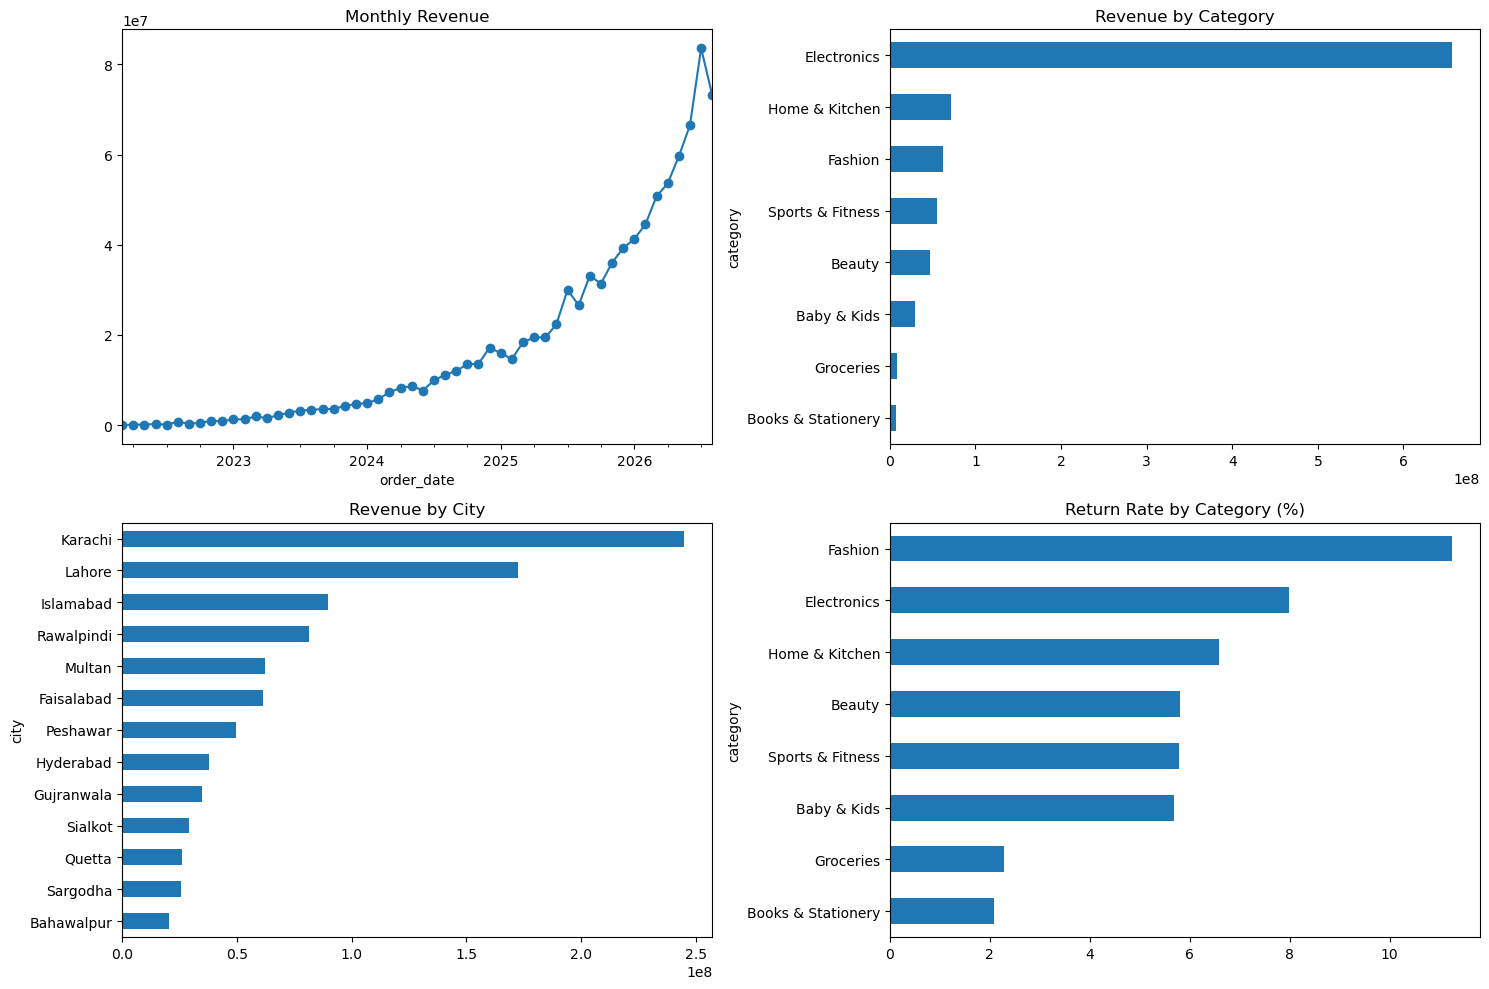

In [28]:
df = pd.read_sql("""SELECT o.*, c.city, c.age, c.membership_type, p.category,
                           o.quantity * o.unit_price * (1 - o.discount) AS revenue
                    FROM orders o JOIN customers c USING(customer_id) JOIN products p USING(product_id)""",
                 cdb, parse_dates=["order_date"])

fig, ax = plt.subplots(2, 2, figsize=(15, 10))
df.groupby(df.order_date.dt.to_period("M")).revenue.sum().plot(ax=ax[0, 0], marker="o", title="Monthly Revenue")
df.groupby("category").revenue.sum().sort_values().plot.barh(ax=ax[0, 1], title="Revenue by Category")
df.groupby("city").revenue.sum().sort_values().plot.barh(ax=ax[1, 0], title="Revenue by City")
(df.groupby("category").returned.mean().sort_values() * 100).plot.barh(ax=ax[1, 1], title="Return Rate by Category (%)")
plt.tight_layout(); plt.show()

In [8]:
print(df.groupby("category").agg(revenue=("revenue", "sum"), return_rate=("returned", "mean")).sort_values("revenue", ascending=False))
m = df.groupby(df.order_date.dt.to_period("M")).revenue.sum(); print(m.tail(8))
print((df.groupby("city").revenue.sum() / df.revenue.sum()).sort_values(ascending=False).head(3))

                          revenue  return_rate
category                                      
Electronics        656,564,123.62         0.08
Home & Kitchen      71,954,661.38         0.07
Fashion             62,178,608.96         0.11
Sports & Fitness    54,534,512.01         0.06
Beauty              46,930,321.28         0.06
Baby & Kids         28,799,414.29         0.06
Groceries            8,024,565.90         0.02
Books & Stationery   7,479,930.49         0.02
order_date
2026-01   41,269,642.42
2026-02   44,537,624.80
2026-03   50,751,998.45
2026-04   53,592,205.29
2026-05   59,632,013.77
2026-06   66,513,495.34
2026-07   83,606,363.19
2026-08   73,170,667.39
Freq: M, Name: revenue, dtype: float64
city
Karachi     0.26
Lahore      0.18
Islamabad   0.10
Name: revenue, dtype: float64


### Business insights
1. **Electronics drives the business (about 70% of net revenue).** It earns 656M of 936M from only 11.5k orders, and two headphone products (Samsung and Anker "Classic") alone give about 20% of all revenue. This is a concentration risk: a stock-out, a supplier problem or a price war on a few electronics items would hit total revenue hard, so these items need priority stock, pricing checks and backup suppliers.
2. **Revenue is growing fast, but the latest month dipped.** Monthly net revenue grew from about 60M (May 2026) to a peak of 84M (July 2026), then fell about 12% to 73M in August. One month is not a trend, but management should check whether the dip is seasonal, stock-related or caused by fewer discounts, before it becomes a pattern.
3. **Fashion has the highest return rate (about 11%) but low revenue.** It has the most orders (12.2k) yet only about 6.6% of revenue, so every return (shipping, restocking, refund) eats into a thin margin. Better size guides and photos would cut returns. Groceries and Books return only about 2%.
4. **Two cities generate almost half the revenue.** Karachi (about 26%) and Lahore (about 18%) give 44% of sales, so delivery speed and marketing in these cities matter most, while mid-size cities like Islamabad are the growth opportunity.
5. **Churn is driven by recency and frequency.** In the Random Forest, days since last order and total orders carry about 30% of the importance each, so a "customer has not bought for X days" alert is the simplest retention trigger.

## Task D: Customer Churn (Machine Learning)
Features use only orders **up to 31 May 2026**. Target = no purchase between 1 Jun and 31 Aug 2026. Nothing from the target window is used in features, so there is no leakage.

In [33]:
# ---- Dates ----
cut = pd.Timestamp("2026-05-31")      # features use orders up to this date
end = pd.Timestamp("2026-08-31")      # target window: 1 Jun - 31 Aug 2026

# ---- Features (only past orders, up to 31 May 2026) ----
past = df[df.order_date <= cut]
feat = past.groupby("customer_id").agg(
    total_orders=("order_id", "count"),
    total_spending=("revenue", "sum"),
    last_order=("order_date", "max"),
    return_rate=("returned", "mean"),
    avg_delivery_days=("delivery_days", "mean"))
feat["avg_order_value"] = feat.total_spending / feat.total_orders
feat["days_since_last_order"] = (cut - feat.last_order).dt.days
feat = feat.drop(columns="last_order")

# age and membership type come from the customers table
feat = feat.join(customers.set_index("customer_id")[["age", "membership_type"]])
feat["membership_type"] = feat.membership_type.map({"Standard": 0, "Silver": 1, "Gold": 2, "Premium": 3})

# ---- Target: churn = 1 if the customer made NO purchase between 1 Jun and 31 Aug 2026 ----
future = df[(df.order_date > cut) & (df.order_date <= end)]
feat["churn"] = (~feat.index.isin(future.customer_id)).astype(int)
print(feat.shape, "| churn rate:", feat.churn.mean().round(3))

# ---- Train / test split ----
X = feat.drop(columns="churn")
y = feat.churn
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# ---- Train a model and report all 6 metrics ----
def evaluate(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    print(name, "- confusion matrix [[TN FP] [FN TP]]:\n", confusion_matrix(y_test, pred), "\n")
    return {"Model": name, "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, prob)}

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))     # scaling helps Logistic Regression
rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)  # max_depth limits overfitting

results = [evaluate("Logistic Regression", lr), evaluate("Random Forest", rf)]
pd.DataFrame(results).set_index("Model")

(6536, 9) | churn rate: 0.49
Logistic Regression - confusion matrix [[TN FP] [FN TP]]:
 [[406 261]
 [100 541]] 

Random Forest - confusion matrix [[TN FP] [FN TP]]:
 [[407 260]
 [103 538]] 



,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.72,0.67,0.84,0.75,0.79
Random Forest,0.72,0.67,0.84,0.75,0.79


**Which model would I use?** Logistic Regression and Random Forest perform almost identically (accuracy about 0.72, recall about 0.84, F1 about 0.75, ROC-AUC about 0.79). Accuracy alone is not enough here: about half the customers churn, and a missed churner (false negative) costs the business a customer, while a false alarm only costs a discount or email, so **recall and F1** matter more. Both models catch about 84% of churners, with precision about 0.67. Because the performance is the same, I would deploy **Logistic Regression**: it is simpler, faster, easier to explain to management (each feature has a coefficient) and its saved file is small.

## Task E: Deep Learning (Neural Network 32 → 16 → 1)

In [35]:
nn = make_pipeline(StandardScaler(),
                   MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu", max_iter=500,
                                 early_stopping=True, random_state=42))   # 32 -> 16 -> 1

results.append(evaluate("Neural Network", nn))     # same train/test data and same 6 metrics
pd.DataFrame(results).set_index("Model")           # table comparing all 3 models

Neural Network - confusion matrix [[TN FP] [FN TP]]:
 [[427 240]
 [128 513]] 



,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.72,0.67,0.84,0.75,0.79
Random Forest,0.72,0.67,0.84,0.75,0.79
Neural Network,0.71,0.68,0.80,0.73,0.79
Neural Network,0.72,0.68,0.80,0.74,0.79


**Was Deep Learning worth it?** No. The neural network (accuracy 0.71, F1 0.73, ROC-AUC 0.78) did not beat Logistic Regression (0.72, 0.75, 0.79) and it found fewer churners (recall 0.78 vs 0.86). With only 8 simple tabular features and about 6,500 customers there is not enough complexity for a neural network to learn, and it is harder to explain and tune, so the extra complexity brings no gain.

In [38]:
# Save Logistic Regression (same performance as Random Forest, but simpler) for the Streamlit app
joblib.dump(lr, "models/churn_model.pkl"); print("Saved churn model: Logistic Regression")

Saved churn model: Logistic Regression


## Task F: NLP Sentiment Analysis

In [39]:
rev = pd.read_sql("SELECT * FROM reviews WHERE TRIM(review_text) != ''", cdb)       # drop empty text
print("Reviews:", len(rev), "| unique texts:", rev.review_text.nunique())
rev = rev.drop_duplicates("review_text")      # same sentence must not appear in both train and test
rev["sentiment"] = pd.cut(rev.rating, [0, 2, 3, 5], labels=["Negative", "Neutral", "Positive"])
print(rev.shape, rev.sentiment.value_counts().to_dict())

Xt_tr, Xt_te, yt_tr, yt_te = train_test_split(rev.review_text, rev.sentiment, test_size=0.2,
                                              stratify=rev.sentiment, random_state=42)
# No stop-word removal: words like "not" carry sentiment. TfidfVectorizer lowercases and drops punctuation.
sent = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
                 ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]).fit(Xt_tr, yt_tr)
pred = sent.predict(Xt_te)
print("Accuracy:", round(accuracy_score(yt_te, pred), 4)); print(classification_report(yt_te, pred))
joblib.dump(sent, "models/sentiment_model.pkl")

Reviews: 25885 | unique texts: 4484
(4484, 7) {'Positive': 2160, 'Neutral': 1387, 'Negative': 937}
Accuracy: 1.0
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       187
     Neutral       1.00      1.00      1.00       278
    Positive       1.00      1.00      1.00       432

    accuracy                           1.00       897
   macro avg       1.00      1.00      1.00       897
weighted avg       1.00      1.00      1.00       897



['models/sentiment_model.pkl']

**Text preparation:** reviews with empty text were removed, and ratings outside 1-5 were already removed in cleaning. Duplicate sentences were dropped before splitting so the test set contains sentences the model has never seen. TF-IDF lowercases text and ignores punctuation; I used 1-2 word combinations and kept stop words, because words like "not" change the meaning ("not recommended").

**Limitation:** The reviews are template-generated: only about 4,500 unique sentences exist among about 26,000 reviews, and each sentiment class uses its own set of phrases. That is why the score is a perfect 1.00, and it will not hold on real customer text. In a quick test the model got unseen wording wrong (e.g. "terrible and broke in two days" was predicted Positive). Also, the labels come from star ratings, which do not always match what the text says, and Roman Urdu reviews are treated as plain tokens.

## Deployment files

In [40]:
import sklearn
open("requirements.txt", "w").write(f"streamlit\npandas\nnumpy\nscikit-learn=={sklearn.__version__}\njoblib=={joblib.__version__}\n")
print(open("requirements.txt").read())

streamlit
pandas
numpy
scikit-learn==1.5.1
joblib==1.4.2



In [41]:
import os
print(os.path.exists("ecommerce_clean.db"))      # should print True
print(os.path.getsize("ecommerce_clean.db"))     # about 8,000,000 (8 MB)

chk = sqlite3.connect("ecommerce_clean.db")
print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", chk))   # 4 tables
chk.close()

True
7921664
        name
0  customers
1   products
2     orders
3    reviews
